In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.preprocessing import StandardScaler

# Load the dataset
df = pd.read_csv('datasets/unsupervised/spotify-track-dataset.csv')

# Drop missing values and deduplicate
df_clean = df.dropna().drop_duplicates(subset='track_id').reset_index(drop=True)

# Identify features
features = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
            'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms']

metadata_cols = ['track_id', 'track_name', 'artists', 'album_name', 'popularity', 'explicit', 'track_genre']

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean[features])

print(f"Preprocessed dataset size: {df_clean.shape[0]} rows, {df_clean.shape[1]} columns.")

Preprocessed dataset size: 89740 rows, 21 columns.


In [2]:
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
count,89740.000000,89740.000000,89740.000000,89740.000000,89740.000000,89740.000000,89740.000000,89740.000000,89740.000000,8.974000e+04
mean,0.562166,0.634458,-8.498994,0.087442,0.328285,0.173415,0.216971,0.469474,122.058134,2.291444e+05
std,0.176692,0.256606,5.221518,0.113278,0.338321,0.323849,0.194885,0.262864,30.117651,1.129458e+05
min,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.586000e+03
25%,0.450000,0.457000,-10.322250,0.036000,0.017100,0.000000,0.098200,0.249000,99.262750,1.730400e+05
50%,0.576000,0.676000,-7.185000,0.048900,0.188000,0.000058,0.132000,0.457000,122.013000,2.132955e+05
75%,0.692000,0.853000,-5.108000,0.085900,0.625000,0.097625,0.279000,0.682000,140.077000,2.642930e+05
max,0.985000,1.000000,4.532000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.237295e+06


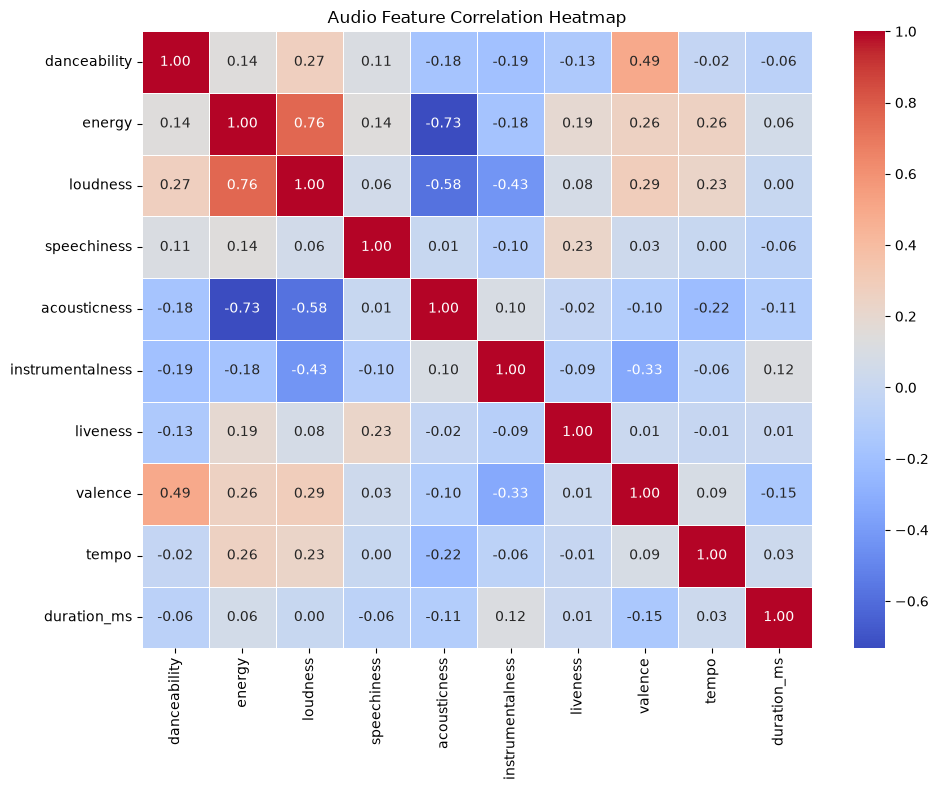

In [3]:
# EDA
import matplotlib.pyplot as plt
import seaborn as sns

# Descriptive statistics
display(df_clean[features].describe())

# Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df_clean[features].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Audio Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

In [4]:
# Dimensionality Reduction (PCA)
from sklearn.decomposition import PCA

# Fit initial PCA to see full cumulative variance
pca_full = PCA(random_state=42)
pca_full.fit(X_scaled)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

# Find components needed for 85% variance
n_components_85 = np.argmax(cumulative_variance >= 0.85) + 1
print(f"Number of components to explain >= 85% variance: {n_components_85}")

# Plot Cumulative Explained Variance
# plt.figure(figsize=(8, 5))
# plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
# plt.axhline(y=0.85, color='r', linestyle=':', label='85% Threshold')
# plt.xlabel('Number of Components')
# plt.ylabel('Cumulative Explained Variance')
# plt.title('Cumulative Explained Variance by PCA Components')
# plt.legend()
# plt.grid(True)
# plt.show()

# Transform data with 85% variance constraint
pca = PCA(n_components=0.85, random_state=42)
X_pca = pca.fit_transform(X_scaled)

Number of components to explain >= 85% variance: 7


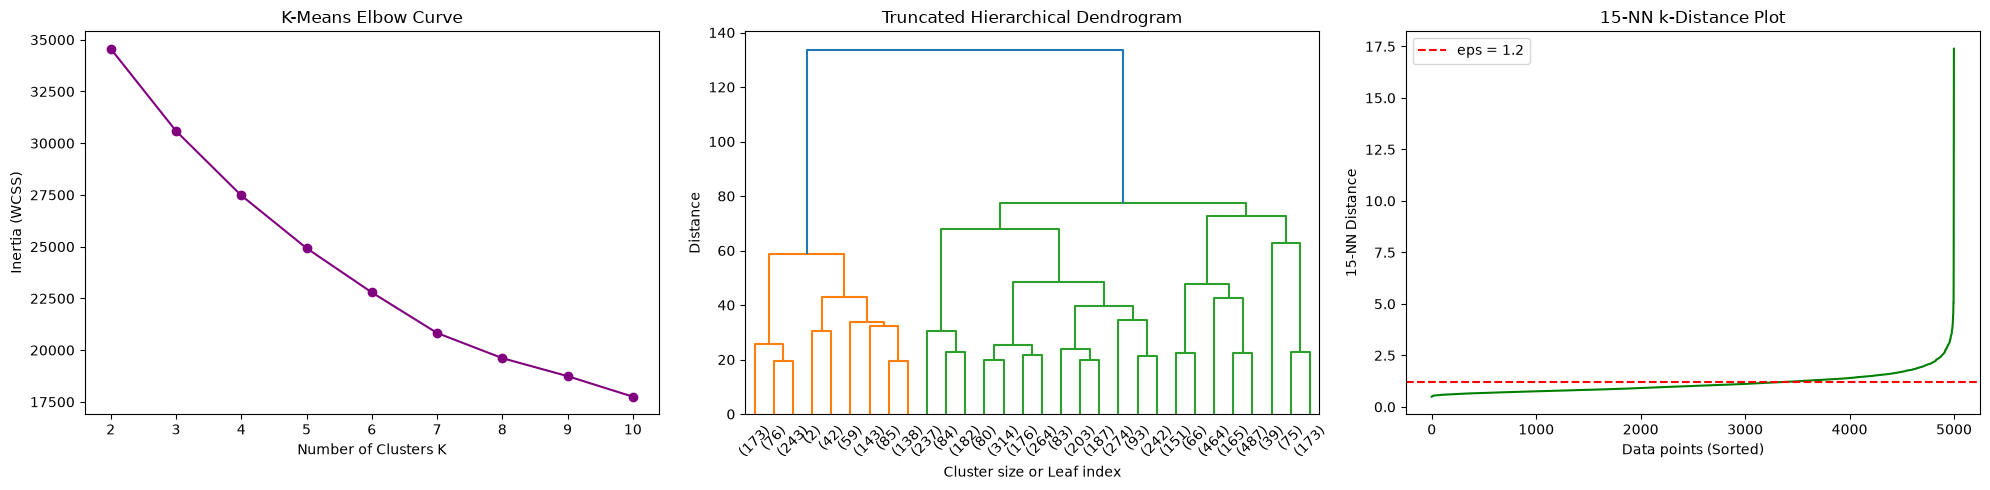

,Model,Clusters Found,Silhouette Score,Davies-Bouldin Index,Noise %
0,K-Means,5,0.180792,1.573799,0.00%
1,Hierarchical,5,0.140645,1.756038,0.00%
2,DBSCAN,2,0.255347,2.454495,16.02%


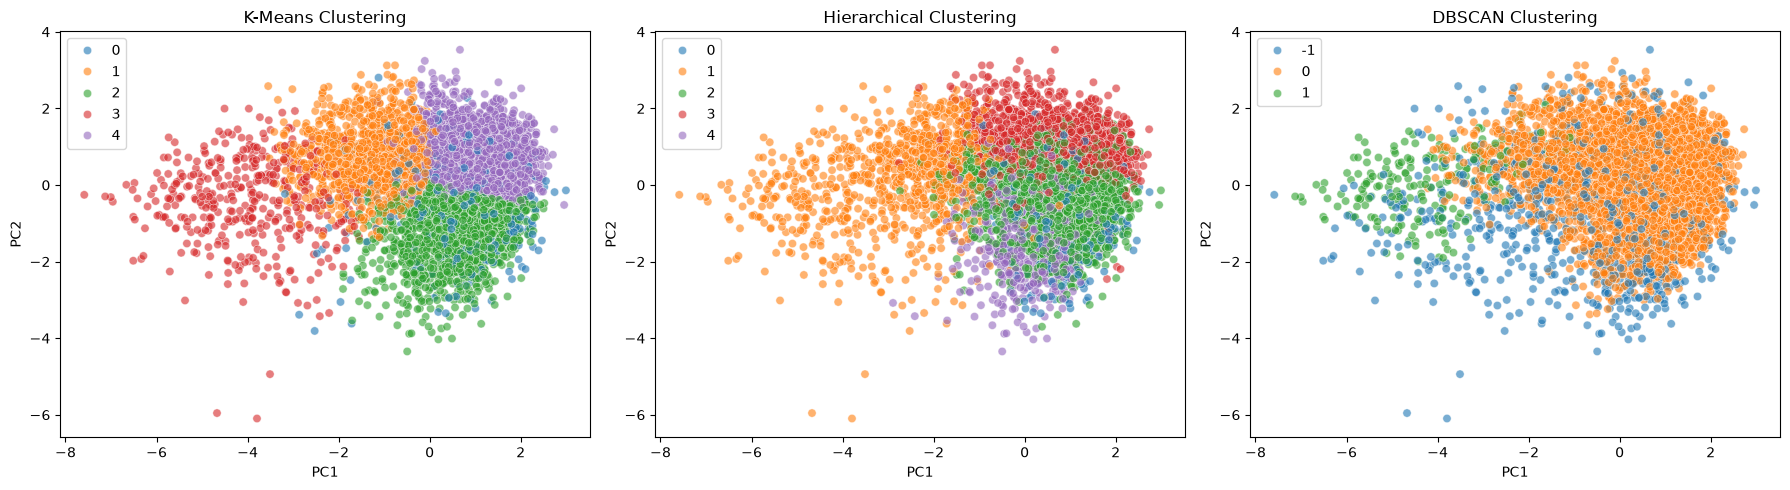

In [5]:
# Evaluation and comparison
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import dendrogram, linkage

# Subsample 5,000 rows
np.random.seed(42)
sample_idx = np.random.choice(len(X_pca), size=5000, replace=False)
X_sample = X_pca[sample_idx]

fig, axs = plt.subplots(1, 3, figsize=(20, 5))

# 1. K-Means Elbow Curve
wcss = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_sample)
    wcss.append(km.inertia_)
axs[0].plot(range(2, 11), wcss, marker='o', color='purple')
axs[0].set_title('K-Means Elbow Curve')
axs[0].set_xlabel('Number of Clusters K')
axs[0].set_ylabel('Inertia (WCSS)')

# 2. Hierarchical Ward-linkage Dendrogram
Z = linkage(X_sample, method='ward')
dendrogram(Z, truncate_mode='lastp', p=30, ax=axs[1], show_leaf_counts=True)
axs[1].set_title('Truncated Hierarchical Dendrogram')
axs[1].set_xlabel('Cluster size or Leaf index')
axs[1].set_ylabel('Distance')

# 3. DBSCAN 15-NN K-distance graph for eps determination
neighbors = NearestNeighbors(n_neighbors=15)
neighbors_fit = neighbors.fit(X_sample)
distances, indices = neighbors_fit.kneighbors(X_sample)
sorted_distances = np.sort(distances[:, 14], axis=0)
axs[2].plot(sorted_distances, color='green')
axs[2].axhline(y=1.2, color='red', linestyle='--', label='eps = 1.2')
axs[2].set_title('15-NN k-Distance Plot')
axs[2].set_xlabel('Data points (Sorted)')
axs[2].set_ylabel('15-NN Distance')
axs[2].legend()

plt.tight_layout()
plt.show()

# Fit models on the sample
km_model = KMeans(n_clusters=5, random_state=42, n_init=10).fit(X_sample)
agg_model = AgglomerativeClustering(n_clusters=5, linkage='ward').fit(X_sample)
db_model = DBSCAN(eps=1.2, min_samples=15).fit(X_sample)

# Calculate metrics
results = []
for name, labels in [('K-Means', km_model.labels_), ('Hierarchical', agg_model.labels_), ('DBSCAN', db_model.labels_)]:
    n_cl = len(set(labels)) - (1 if -1 in labels else 0)
    sil = silhouette_score(X_sample, labels) if n_cl > 1 else np.nan
    db_idx = davies_bouldin_score(X_sample, labels) if n_cl > 1 else np.nan
    noise_pct = (labels == -1).sum() / len(labels) * 100 if -1 in labels else 0.0
    results.append({
        'Model': name,
        'Clusters Found': n_cl,
        'Silhouette Score': sil,
        'Davies-Bouldin Index': db_idx,
        'Noise %': f"{noise_pct:.2f}%"
    })

metrics_df = pd.DataFrame(results)
display(metrics_df)

# 2D PCA Scatterplot Comparison
pca_2d = PCA(n_components=2, random_state=42)
X_sample_2d = pca_2d.fit_transform(X_sample)

fig, axs = plt.subplots(1, 3, figsize=(18, 5))
models_labels = [km_model.labels_, agg_model.labels_, db_model.labels_]
names = ['K-Means', 'Hierarchical', 'DBSCAN']
for idx, labels in enumerate(models_labels):
    sns.scatterplot(x=X_sample_2d[:, 0], y=X_sample_2d[:, 1], hue=labels, palette='tab10', legend='full', alpha=0.6, ax=axs[idx])
    axs[idx].set_title(f"{names[idx]} Clustering")
    axs[idx].set_xlabel("PC1")
    axs[idx].set_ylabel("PC2")
plt.tight_layout()
plt.show()

In [6]:
# Fit K-Means on full PCA-transformed dataset
kmeans_final = KMeans(n_clusters=5, random_state=42, n_init=10)
df_clean['cluster'] = kmeans_final.fit_predict(X_pca)

# Calculate mean features for each cluster
cluster_stats = df_clean.groupby('cluster')[features].mean()
print("--- Cluster Audio Profiles (Means) ---")
display(cluster_stats)

# Define mood mapping dynamically based on stats
mood_mapping = {
    0: 'Chill Acoustic & Slow',
    1: 'Intense Workout / Energetic',
    2: 'Upbeat Party & Dance Pop',
    3: 'Calm Instrumental & Study',
    4: 'Melancholic / Sad'
}

df_clean['mood_group'] = df_clean['cluster'].map(mood_mapping)

# Compute Euclidean distance to assigned cluster centroid
centroids = kmeans_final.cluster_centers_
assigned_centroids = centroids[df_clean['cluster']]
distances = np.linalg.norm(X_pca - assigned_centroids, axis=1)
df_clean['distance_to_centroid'] = distances

--- Cluster Audio Profiles (Means) ---


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
cluster,,,,,,,,,,
0,0.474934,0.816665,-6.112655,0.082076,0.068767,0.253129,0.257448,0.320162,135.908893,264417.423339
1,0.691294,0.730773,-6.434362,0.094053,0.210046,0.057473,0.199866,0.683812,121.053507,211956.875218
2,0.366680,0.205258,-20.373467,0.052484,0.813903,0.793830,0.172365,0.183220,103.683366,222728.126136
3,0.574659,0.673539,-11.065829,0.821543,0.723472,0.008833,0.666403,0.445901,102.385560,217601.234291
4,0.528528,0.386366,-10.626323,0.055586,0.671025,0.044814,0.184458,0.407840,113.397089,214964.731501


In [7]:
import pickle

def recommend_mood_playlist(selected_mood, n_songs=10, exclude_explicit=False):
    # Filter by mood
    candidates = df_clean[df_clean['mood_group'].str.lower() == selected_mood.lower()].copy()

    if candidates.empty:
        return f"Mood '{selected_mood}' not found. Choose from: {list(mood_mapping.values())}"

    # Filter explicit songs if flag is set
    if exclude_explicit:
        candidates = candidates[candidates['explicit'] == False]

    # MinMax scaling values locally within candidates for combination
    min_dist, max_dist = candidates['distance_to_centroid'].min(), candidates['distance_to_centroid'].max()
    candidates['proximity_score'] = 1 - ((candidates['distance_to_centroid'] - min_dist) / (max_dist - min_dist + 1e-9))

    min_pop, max_pop = candidates['popularity'].min(), candidates['popularity'].max()
    candidates['popularity_score'] = (candidates['popularity'] - min_pop) / (max_pop - min_pop + 1e-9)

    # Calculate weighted score
    candidates['score'] = (0.6 * candidates['proximity_score']) + (0.4 * candidates['popularity_score'])

    recommendations = candidates.sort_values(by='score', ascending=False).head(n_songs)
    return recommendations[['track_name', 'artists', 'popularity', 'explicit', 'score']]

# Test recommendations
print("Testing Recommendations:")
display(recommend_mood_playlist('Upbeat Party & Dance Pop', n_songs=5))
display(recommend_mood_playlist('Chill Acoustic & Slow', n_songs=5, exclude_explicit=True))

# Save objects using pickle
artifacts = {
    'scaler': scaler,
    'pca': pca,
    'kmeans': kmeans_final,
    'mood_mapping': mood_mapping
}

with open('unsupervised-learning/artifacts/playlist_generator_models.pkl', 'wb') as f:
    pickle.dump(artifacts, f)
print("\nPipeline artifacts saved successfully as 'unsupervised-learning/artifacts/playlist_generator_models.pkl'.")

Testing Recommendations:


,track_name,artists,popularity,explicit,score
28432,everything i wanted,Billie Eilish,86,False,0.966749
49010,YKWIM?,Yot Club,84,False,0.955446
78685,Fourth of July,Sufjan Stevens,81,False,0.950252
10278,Lights Are On,Tom Rosenthal,81,False,0.948291
3420,Experience,Ludovico Einaudi;Daniel Hope;I Virtuosi Italiani,79,False,0.940661


,track_name,artists,popularity,explicit,score
57111,Tití Me Preguntó,Bad Bunny,97,False,0.973407
2002,Sweater Weather,The Neighbourhood,93,False,0.967215
57249,Ojitos Lindos,Bad Bunny;Bomba Estéreo,95,False,0.963391
67617,Blinding Lights,The Weeknd,91,False,0.957087
67683,Call Out My Name,The Weeknd,89,False,0.956191



Pipeline artifacts saved successfully as 'unsupervised-learning/artifacts/playlist_generator_models.pkl'.


The new track belongs to Cluster: 1
Assigned Mood Group: Intense Workout / Energetic


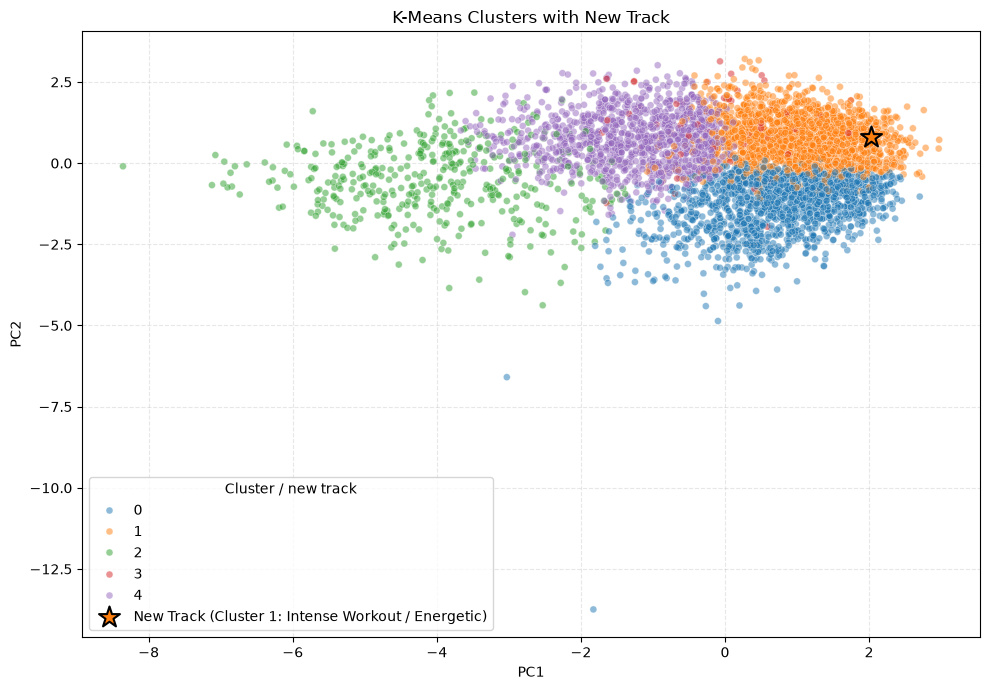

In [8]:
# load model onto pickle and predict new tracks
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# 1. Load the saved model, scaler, PCA, and mood mapping
with open('unsupervised-learning/artifacts/playlist_generator_models.pkl', 'rb') as f:
    loaded_artifacts = pickle.load(f)

loaded_scaler = loaded_artifacts['scaler']
loaded_pca = loaded_artifacts['pca']
loaded_kmeans = loaded_artifacts['kmeans']
loaded_mood_mapping = loaded_artifacts['mood_mapping']

# Define a new track profile with custom audio features - highly danceable, energetic, loud, and electronic
new_track_data = pd.DataFrame([{
    'danceability': 0.85,
    'energy': 0.90,
    'loudness': -4.5,
    'speechiness': 0.08,
    'acousticness': 0.05,
    'instrumentalness': 0.12,
    'liveness': 0.15,
    'valence': 0.75,
    'tempo': 125.0,
    'duration_ms': 210000
}])

# 3. Scale the new track features using the loaded scaler
new_track_scaled = loaded_scaler.transform(new_track_data)

# 4. Project the scaled features using the loaded PCA
new_track_pca = loaded_pca.transform(new_track_scaled)

# 5. Predict the cluster group
predicted_cluster = loaded_kmeans.predict(new_track_pca)[0]
predicted_mood = loaded_mood_mapping[predicted_cluster]

print(f"The new track belongs to Cluster: {predicted_cluster}")
print(f"Assigned Mood Group: {predicted_mood}")


# 6. Plot the new track with the predicted cluster on a 2D PCA scatterplot
plot_idx = np.random.default_rng(42).choice(
    len(X_pca), size=min(5000, len(X_pca)), replace=False
)
pca_2d = PCA(n_components=2, random_state=42)
training_points_2d = pca_2d.fit_transform(X_pca[plot_idx])
new_track_2d = pca_2d.transform(new_track_pca)
cluster_labels = df_clean.iloc[plot_idx]['cluster'].to_numpy()
cluster_colors = sns.color_palette('tab10', n_colors=loaded_kmeans.n_clusters)

plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=training_points_2d[:, 0],
    y=training_points_2d[:, 1],
    hue=cluster_labels,
    hue_order=list(range(loaded_kmeans.n_clusters)),
    palette=cluster_colors,
    alpha=0.5,
    s=25,
    legend='full'
)
plt.scatter(
    new_track_2d[0, 0],
    new_track_2d[0, 1],
    color=cluster_colors[int(predicted_cluster)],
    marker='*',
    s=250,
    label=f'New Track (Cluster {predicted_cluster}: {predicted_mood})',
    edgecolors='black',
    linewidths=1.5,
    zorder=5
)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('K-Means Clusters with New Track')
plt.legend(title='Cluster / new track', loc='best')
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()
